# Chapitre 11 - Cours 7 : jointures de flux et tolérance aux pannes

Ce dernier cours couvre les sous-sections *Stream Joins* (*Stream-stream join (window
join)*, *Stream-table join (stream enrichment)*, *Table-table join (materialized view
maintenance)*, *Time-dependence of joins*) et *Fault Tolerance* (*Microbatching and
checkpointing*, *Atomic commit revisited*, *Idempotence*, *Rebuilding state after a
failure*). Les opérateurs de jointure (`SearchClickJoin`, `enrich`, `TimelineView`) et le
job à état avec pannes injectées (`run_stateful_job`, `FencedSink`) sont dans
[`ddia/streams.py`](../../ddia/streams.py).

**Plan.**

1. Jointure flux-flux : recherches et clics.
2. Jointure flux-table : enrichir un flux.
3. Jointure table-table : maintenir des timelines.
4. La dépendance temporelle des jointures.
5. Micro-lots et points de contrôle.
6. La validation atomique revisitée.
7. L'idempotence (et le fencing).
8. Reconstruire l'état après une panne.

In [1]:
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import streams as st
from ddia.diagrams import Diagram
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Jointure flux-flux (section *Stream-stream join (window join)*)

Les jobs par lots joignent des jeux de données par clé (chapitre 10) ; le
traitement de flux, qui généralise les pipelines au cas incrémental et non borné, a le
même besoin, compliqué par le fait que de nouveaux événements peuvent arriver à tout
moment. Trois cas se présentent : flux-flux, flux-table, table-table.

**Flux-flux.** Un moteur de recherche enregistre un événement à chaque recherche et un
autre à chaque clic sur un résultat. Pour calculer le **taux de clic** (click-through
rate) de chaque résultat, il faut réunir les deux événements, liés par l'identifiant de
session (même besoin dans la publicité). Le clic peut ne jamais venir (recherche
abandonnée), venir après quelques secondes ou après des jours (onglet oublié), et même
arriver **avant** la recherche à cause des délais réseau. On choisit donc une **fenêtre**
de jointure, par exemple une heure. Notez qu'embarquer les détails de la recherche dans
l'événement de clic ne remplace pas la jointure : on ne connaîtrait que les recherches
cliquées, jamais celles qui ne l'ont pas été, donc aucun taux.

L'opérateur garde un **état** : les événements de la dernière heure, indexés par
session. À chaque recherche ou clic, il l'ajoute à l'index correspondant et consulte
l'autre index ; si la paire est complète, il émet « tel résultat a été cliqué ». Si une
recherche expire sans clic, il émet « non cliqué ». Simulons 8 000 sessions sur deux
heures : 40 % cliquent, après un délai log-normal (médiane 20 s, avec une longue queue),
et chaque événement subit un délai réseau aléatoire.

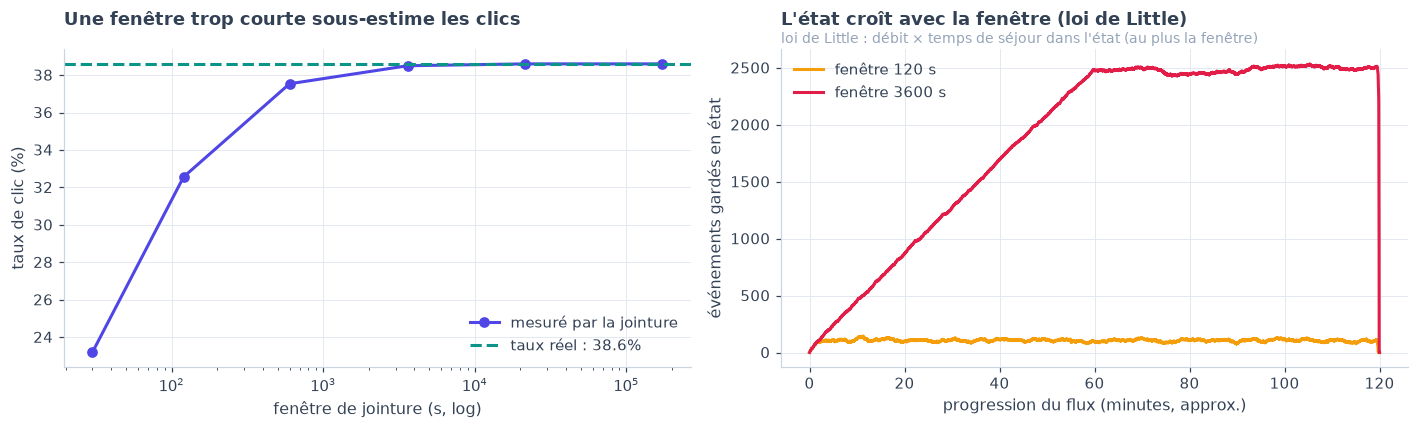

,taux de clic mesuré,état max (événements)
fenêtre,,
30,0.232,55
120,0.326,144
600,0.375,491
3600,0.385,2535
21600,0.386,4957
172800,0.386,4957


In [2]:
n_sess = 8000
t_search = np.sort(rng.uniform(0, 7200, n_sess))
clique = rng.random(n_sess) < 0.4
delai_clic = rng.lognormal(np.log(20), 1.8, n_sess)
evts = []                                                  # (arrivée, kind, session, t_événement)
for s in range(n_sess):
    evts.append((t_search[s] + rng.lognormal(0, 1), "search", s, t_search[s]))
    if clique[s]:
        tc = t_search[s] + delai_clic[s]
        evts.append((tc + rng.lognormal(0, 1), "click", s, tc))
evts.sort()
rows, etats = [], {}
for W in [30, 120, 600, 3600, 6 * 3600, 48 * 3600]:
    j = st.SearchClickJoin(window=W)
    for _, kind, s, t in evts:
        j.process(kind, s, t)
    j.flush()
    oui = sum(o[0] == "clicked" for o in j.out)
    non = sum(o[0] == "not_clicked" for o in j.out)
    rows.append({"fenêtre": W, "taux de clic mesuré": oui / (oui + non), "état max (événements)": max(j.state_size)})
    etats[W] = j.state_size
J = pd.DataFrame(rows).set_index("fenêtre")
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax.semilogx(J.index, J["taux de clic mesuré"] * 100, "o-", color=INDIGO, label="mesuré par la jointure")
ax.axhline(clique.mean() * 100, color=TEAL, ls="--", label=f"taux réel : {clique.mean():.1%}")
ax.set_xlabel("fenêtre de jointure (s, log)"); ax.set_ylabel("taux de clic (%)")
ax.set_title("Une fenêtre trop courte sous-estime les clics")
ax.legend(loc="lower right")
for W, c in [(120, AMBER), (3600, ROSE)]:
    ax2.plot(np.arange(len(etats[W])) / len(etats[W]) * 7200 / 60, etats[W], color=c, label=f"fenêtre {W} s")
ax2.set_xlabel("progression du flux (minutes, approx.)"); ax2.set_ylabel("événements gardés en état")
ax2.set_title("L'état croît avec la fenêtre (loi de Little)")
subtitle(ax2, "loi de Little : débit × temps de séjour dans l'état (au plus la fenêtre)")
ax2.legend()
plt.tight_layout(); plt.show()
J.round(3)

Avec une fenêtre de 30 secondes, on rate la majorité des clics tardifs et l'on mesure un
taux de clic bien inférieur au taux réel (23 % au lieu de 38,6 %) ; il faut une fenêtre
d'environ une heure pour capter presque tous les clics de la longue queue. Mais l'état
grandit proportionnellement : d'après la loi de Little, il vaut le débit des événements
multiplié par leur temps de séjour dans l'état, qui atteint la fenêtre entière pour toutes
les recherches qui ne seront jamais cliquées. Le choix de la
fenêtre est donc un compromis entre exactitude et mémoire, et dépend de la distribution
des délais (exercice 11.10).

> **À retenir.** Une jointure flux-flux garde les événements récents des deux flux,
> indexés par clé, sur une fenêtre ; elle émet les paires et les absences de paire. La
> fenêtre arbitre entre exactitude et taille de l'état.